<a href="https://colab.research.google.com/github/Ductuk8/laptop-price-prediction/blob/main/Laptop_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dự đoán giá laptop


Các bước xử lý: đọc dữ liệu → khám phá dữ liệu → làm sạch và tạo đặc trưng → chia train/test → tiền xử lý → huấn luyện mô hình → đánh giá và so sánh.

## 1. Khai báo thư viện

In [89]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## 2. Đọc dữ liệu

In [90]:

#Đọc dữ liệu
import pandas as pd
#Công cụ để làm việc với data


url = "https://raw.githubusercontent.com/Ductuk8/laptop-price-prediction/main/laptops_train_formatted.xlsx"
df = pd.read_excel(url)
#df = pd.read_excel('/content/laptops_train_formatted.xlsx')
#Đọc và lưu tên df

df.columns = df.columns.str.strip()
#Xóa khoảng thừa ở cột (Được xử lý ngay sau bước info data)


df.head()
#In 5 dòng đầu tiên


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,NaN,1.37kg,11912523.48
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,NaN,1.34kg,7993374.48
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,NaN,1.86kg,5112900.00
3,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,NaN,1.83kg,22563005.40
4,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,NaN,1.37kg,16037611.20


In [91]:
# Đọc số dòng và cột
print(df.shape)
# Đọc tên các cột
print(df.columns)

(977, 13)
Index(['Manufacturer', 'Model Name', 'Category', 'Screen Size', 'Screen',
       'CPU', 'RAM', 'Storage', 'GPU', 'Operating System',
       'Operating System Version', 'Weight', 'Price'],
      dtype='object')


# 3. Info data


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 977 entries, 0 to 976
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Manufacturer              977 non-null    object 
 1   Model Name                977 non-null    object 
 2   Category                  977 non-null    object 
 3   Screen Size               977 non-null    object 
 4   Screen                    977 non-null    object 
 5   CPU                       977 non-null    object 
 6   RAM                       977 non-null    object 
 7   Storage                   977 non-null    object 
 8   GPU                       977 non-null    object 
 9   Operating System          977 non-null    object 
 10  Operating System Version  841 non-null    object 
 11  Weight                    977 non-null    object 
 12  Price                     977 non-null    float64
dtypes: float64(1), object(12)
memory usage: 99.4+ KB


#Ta đọc được
1. Kích thước 977 dòng và 13 cột
2. Ngoài Price là kiểu số thực thì còn lại là dạng chuỗi.
Vì vậy các chỉ số Screen Size, RAM, Weight, Storage chưa dùng được cần chuyển sang dạng số.
3. Ở Operating System Version thiếu |977 - 841 = 136|.
-> Xử lý bằng cách điền vào ô trống bằng giá trị xuất hiện nhiều nhất của cột đó. (SimpleImputer)
4. Cột Storage có khoảng trắng ở đầu
-> Xử lý ngay sau bước đọc dữ liệu


#4. Visualization <Hình dung>

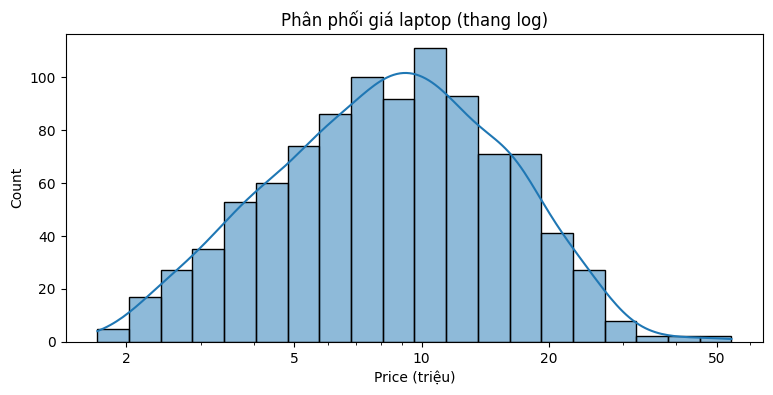

In [93]:
plt.figure(figsize=(9, 4))
sns.histplot(df['Price'], kde=True, log_scale=True)
#Tạo khung vẽ. vẽ histogram, thêm đường cong, đổi trục ngang sang thang log.

# Chọn các vạch giá muốn hiện (đơn vị gốc), rồi đổi nhãn sang triệu
plt.xticks([2e6, 5e6, 1e7, 2e7, 5e7])
#Vì trục x dùng thang log, nên dùng cách khoảng 2,5,10,... để có thể bao phủ được các giá trị từ 2 đến 50tr
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:g}'))
plt.gca().xaxis.set_minor_formatter(FuncFormatter(lambda x, _: ''))


plt.title('Phân phối giá laptop (thang log)')
plt.xlabel('Price (triệu)')
plt.ylabel('Count')
plt.show()

1. Đỉnh phân phối nằm quanh mốc 10 triệu. Đạt đỉnh trong vùng 8 - 12 triệu.
2. Bên trái ta thấy rất ít máy trong khoảng từ 2-3 triệu.
3. Bên trái từ 15 - 20 triệu số máy giảm dần. Khoảng 40-50 triệu số máy giảm xuống mức 8-5 máy.
4. Biểu đồ hình dạng chuông khá cân đối, khá đẹp.

#5. Làm sạch dữ liệu

In [94]:
data = df.copy()
data = data.drop_duplicates()
data = data.dropna(subset=["Price"])
##data["Price"] = pd.to_numeric(data["Price"], errors="coerce")
##data = data.dropna(subset=["Price"])
data = data[data["Price"] > 0].copy()

In [95]:
def first_number(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"(\d+(?:\.\d+)?)", str(value).replace(",", "."))
    return float(match.group(1)) if match else np.nan


data["Screen_Size_inch"] = data["Screen Size"].apply(first_number)
data["RAM_GB"]           = data["RAM"].apply(first_number)
data["Weight_kg"]        = data["Weight"].apply(first_number)


data[["Screen Size", "Screen_Size_inch", "RAM", "RAM_GB", "Weight", "Weight_kg"]].head()

,Screen Size,Screen_Size_inch,RAM,RAM_GB,Weight,Weight_kg
0,"13.3""",13.3,8GB,8.0,1.37kg,1.37
1,"13.3""",13.3,8GB,8.0,1.34kg,1.34
2,"15.6""",15.6,8GB,8.0,1.86kg,1.86
3,"15.4""",15.4,16GB,16.0,1.83kg,1.83
4,"13.3""",13.3,8GB,8.0,1.37kg,1.37


1. Viết hàm xử lý chuyển chuỗi sang số. Nếu ô có có chuỗi thì chuyển chuỗi thành số.

2. Áp dụng hàm xử lý vào các cột. Sau đó lưu nó vào cột mới.

3. In ra để kiểm tra

In [96]:
def storage_gb(text, kind):
    """Cộng tổng dung lượng (GB) của loại ổ `kind` trong chuỗi Storage."""
    total = 0.0
    for num, unit, typ in re.findall(
        r"(\d+(?:\.\d+)?)\s*(tb|gb)\s*(ssd|hdd|flash|hybrid)", str(text).lower()
    ):
        if typ == kind:
            total += float(num) * (1000 if unit == "tb" else 1)
    return total

data["SSD_GB"]    = data["Storage"].apply(lambda t: storage_gb(t, "ssd"))
data["HDD_GB"]    = data["Storage"].apply(lambda t: storage_gb(t, "hdd"))
data["Flash_GB"]  = data["Storage"].apply(lambda t: storage_gb(t, "flash"))
data["Hybrid_GB"] = data["Storage"].apply(lambda t: storage_gb(t, "hybrid"))

data[["Storage", "SSD_GB", "HDD_GB", "Flash_GB", "Hybrid_GB"]].drop_duplicates("Storage").head(10)

,Storage,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB
0,128GB SSD,128.0,0.0,0.0,0.0
1,128GB Flash Storage,0.0,0.0,128.0,0.0
2,256GB SSD,256.0,0.0,0.0,0.0
3,512GB SSD,512.0,0.0,0.0,0.0
5,500GB HDD,0.0,500.0,0.0,0.0
6,256GB Flash Storage,0.0,0.0,256.0,0.0
18,1TB HDD,0.0,1000.0,0.0,0.0
20,32GB Flash Storage,0.0,0.0,32.0,0.0
21,128GB SSD + 1TB HDD,128.0,1000.0,0.0,0.0
28,256GB SSD + 256GB SSD,512.0,0.0,0.0,0.0


1. Hàm đọc chuỗi Storage và trả về tổng dung lượng bằng GB của một loại ổ cứng mà bạn chọn.
2. Hàm nhận một chuỗi gồm số GB và loại ổ. Hàm sẽ tách chuỗi đó và tính tổng lượng GB của mỗi ổ.
3. Áp dụng thành 4 cột tương tự với 4 ổ khác nhau
4. Kiểm tra sau khi chạy.

In [97]:
drop_cols = ["Price", "Screen Size", "RAM", "Weight", "Storage"]
X = data.drop(columns=[c for c in drop_cols if c in data.columns])
y = data["Price"]
#X là danh sách các cột cần bỏ khỏi X.
#Ta bỏ Price vì đây là đáp án. Nếu để trong X, thì sẽ rò rỉ dữ liệu( nhìn trộm) làm điểm số cao giả tạo
#4 cái còn lại bỏ vì ta đã có bản thay thế từ chuỗi sang số


print("X:", X.shape, "| y:", y.shape)
#print(X.columns.tolist())
for c in X.columns:
    print(c)

X: (977, 15) | y: (977,)
Manufacturer
Model Name
Category
Screen
CPU
GPU
Operating System
Operating System Version
Screen_Size_inch
RAM_GB
Weight_kg
SSD_GB
HDD_GB
Flash_GB
Hybrid_GB


1. Tách X(Đặc trưng) và y(nhãn)
2. X(đặc trưng): thông tin đầu vào những thông tin về laptop
3. Y(nhãn): đáp án cần dự đoán, giá
4. Mô hình học: X thế này thì y thế kia.

In [98]:
# Kiểm tra các cột số sau khi làm sạch và tạo đặc trưng
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,977.0,1.001899e+07,6.306430e+06,1706374.80,5326308.0,8527428.00,13115700.0,54232308.0
Screen_Size_inch,977.0,1.505261e+01,1.418950e+00,10.10,14.0,15.60,15.6,18.4
RAM_GB,977.0,8.528147e+00,4.997487e+00,2.00,4.0,8.00,8.0,32.0
Weight_kg,977.0,2.039128e+00,6.660094e-01,0.69,1.5,2.02,2.3,4.7
SSD_GB,977.0,1.897769e+02,1.894002e+02,0.00,0.0,256.00,256.0,1024.0
HDD_GB,977.0,4.177687e+02,5.312961e+02,0.00,0.0,0.00,1000.0,2000.0
Flash_GB,977.0,4.061412e+00,2.699872e+01,0.00,0.0,0.00,0.0,512.0
Hybrid_GB,977.0,1.543501e+00,3.586942e+01,0.00,0.0,0.00,0.0,1000.0


Kiểm tra chất lượng trước khi đưa dữ liệu vào mô hình.

#6. Chia tập train/test



In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
    #Mỗi lần chạy ra cùng một cách chia
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)


print("Trung bình giá train:", round(y_train.mean()))
print("Trung bình giá test :", round(y_test.mean()))
#Đánh giá hai số này nên gần nhau. Nếu chênh lệch quá lớn thì cách chia bị lệch.

X_train: (781, 15)
X_test : (196, 15)
Trung bình giá train: 10107195
Trung bình giá test : 9667543


Để biết mô hình tốt đến đâu với laptop chưa từng thấy. Nên ta dùng 80% để tập train, dữ liệu để mô hình học.
20% để test, dữ liệu để chấm điểm sau khi học xong.

#7. Tiền xử lý dữ liệu

Giá trị thiếu: dữ liệu chỉ thiếu ở cột Operating System Version (136 ô). Ta điền ở bước tiền xử lý, sau khi chia train/test, để giá trị điền chỉ học từ tập train. Nếu điền trước, thông tin của tập test sẽ lọt vào, điểm đánh giá sẽ cao hơn thực tế (gọi là rò rỉ dữ liệu).

Ngoại lệ: ta giữ nguyên. Đó là 29 laptop cao cấp giá thật, không phải lỗi nhập liệu. Xóa đi thì mô hình sẽ không dự đoán được máy đắt.”

In [100]:
#Chia cột thành số và chữ
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
#Phân loại để biết cột nào cần xử lý kiểu nào


#Dây chuyền cho cột số
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
#Điền ô trống (điền trung vị) và chuẩn hóa các cột có thang đo khác nhau


#Dây chuyền cho cột chữ
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
#Điền ô trống (điền giá trị xuất hiện nhiều nhất) và đổi chữ thành số


#Ghép hai dây chuyền
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)
#Gom lại thành một bộ xử lý duy nhất và giao đúng cột cho đúng dây chuyền


print("Biến số:", numeric_features)
print("Biến phân loại:", categorical_features)
#Kiếm tra

Biến số: ['Screen_Size_inch', 'RAM_GB', 'Weight_kg', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']
Biến phân loại: ['Manufacturer', 'Model Name', 'Category', 'Screen', 'CPU', 'GPU', 'Operating System', 'Operating System Version']


#8. Huấn luyện mô hình

In [101]:
#Khai báo hai mô hình
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42, min_samples_leaf=2, n_jobs=-1
    )
}
#Tạo một "danh sách" gồm hai mô hình, mỗi mô hình 1 tên

#Chuẩn bị
fitted_models = {}
predictions = {}
#Cất các mô hình đã học xong và cất giá mà mỗi mô hình dự đoán cho tập test

#Vòng lặp huấn luyện
for name, estimator in models.items():
#làm lần lượt từng mô hình trong danh sách.
#Vòng 1 là Linear Regression
#Vòng 2 là Random Forest.

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])
    #Dữ liệu -> xử lý -> mô hình học hoặc dự đoán

    model.fit(X_train, y_train)
    #Bộ tiền xử lý học từ X_train rồi biến X_train thành số
    #Mô hình học thật sự học giữa các đặc trưng và giá y_train

    y_pred = model.predict(X_test)
    #Cho mô hình đoán giá của 20%test

    fitted_models[name] = model
    predictions[name] = y_pred
    print(f"Đã huấn luyện: {name}")
    #Cất mô hình và kết quả dự đoán vào hai "hộp" rồi in ra

Đã huấn luyện: Linear Regression
Đã huấn luyện: Random Forest


1. Linear Regression: Tìm một công thức cộng dồn, kiểu: giá = a×RAM + b×SSD + ... + c
2. Random Forest: Xây nhiều cây quyết định (kiểu câu hỏi “RAM trên 8GB không? SSD lớn không?...”) rồi lấy trung bình dự đoán của các cây

#9. Đánh giá và so sánh mô hình

In [102]:
results = []
#Cất điểm
for name, y_pred in predictions.items():
  #V1: Linear Regression, vòng 2: Random Forest
    results.append({
        "Model": name,
        "R2": r2_score(y_test, y_pred),
        #So sánh giá thật với giá dự đoán
        "MAE": mean_absolute_error(y_test, y_pred),
        #Tính MAE: trung bình mỗi máy bị lệch bao nhiêu tiền
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
        #Tính RMSE: bình phương sai số, lấy trung bình, rồi lấy căn bậc hai
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df)
#Sắp xếp cái nào tốt nhất (RMSE từ nhỏ đến lớn)

,Model,R2,MAE,RMSE
0,Linear Regression,0.805492,1.866866e+06,2.651882e+06
1,Random Forest,0.789826,1.689247e+06,2.756606e+06


1. Hai mô hình rất sát nhau: R² chỉ chênh khoảng 0,016.
2. Linear Regression thắng ở R² và RMSE.
3. Random Forest thắng ở MAE, nghĩa là với máy thông thường nó đoán sát hơn, nhưng thỉnh thoảng lệch lớn ở máy đắt nên RMSE kém hơn.
4. Dùng RMSE vì phạt nặng các lần đoán lệch lớn. R^2 Muốn 1 con số tổng quát về mức độ phù hợp của mô hình. MAE muốn biết sai số điển hình của một máy, ít bị máy đắt kéo lệch


In [103]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
#Lấy mô hình đã học xong
best_predictions = predictions[best_model_name]
#lấy dự đoán mô hình
print("Mô hình tốt nhất theo RMSE:", best_model_name)
#In mô hình đã chọn
print(f"R2   : {r2_score(y_test, best_predictions):,.4f}")
print(f"MAE  : {mean_absolute_error(y_test, best_predictions):,.2f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, best_predictions)):,.2f}")
#Tính lại  và in điểm của mô hình tốt nhất

Mô hình tốt nhất theo RMSE: Linear Regression
R2   : 0.8055
MAE  : 1,866,866.34
RMSE : 2,651,881.69


1. Mô Hình được khoảng 80,6% sự khác nhau về giá giữa các laptop
2. Trung bình mỗi máy bị đoán lệch khoảng 1,87 triệu. Giá trung bình tập test khoảng 9,67 triệu, nên sai số khoảng 19%
3. RMSE = 2,65 triệu: lớn hơn MAE, cho thấy một số máy bị lệch khá nhiều

#10. So sánh giá thật và giá dự đoán

In [104]:
comparison = pd.DataFrame({
    "Price_Actual": y_test,
    "Price_Predicted": best_predictions
})
#Ghép giá thật và giá dự đoán

comparison["Error"] = comparison["Price_Predicted"] - comparison["Price_Actual"]
#Error = dự đoán - thực tế
#Error dương: mô hình đoán cao hơn giá thật.
#Error âm: mô hình đoán thấp hơn giá thật.

display(comparison.head(15))
#Hiển thị 15 máy



,Price_Actual,Price_Predicted,Error
199,9292140.00,9.368017e+06,7.587727e+04
542,10181340.00,1.102290e+07,8.415598e+05
174,8207316.00,9.103431e+06,8.961155e+05
764,7549308.00,5.866222e+06,-1.683086e+06
66,3900831.48,5.153005e+06,1.252174e+06
494,11283948.00,1.546304e+07,4.179095e+06
695,2391948.00,5.284263e+06,2.892315e+06
547,4111216.20,8.025853e+06,3.914637e+06
914,4437108.00,4.586793e+06,1.496850e+05
158,9327708.00,8.586786e+06,-7.409224e+05


1. Có máy đoán rất sát
2. Có máy đoán lệch nhiều
3. Máy rẻ bị đoán cao hơn nhiều.
4. Sai số 2,5 triệu ảnh hưởng khác nhau tùy mức giá

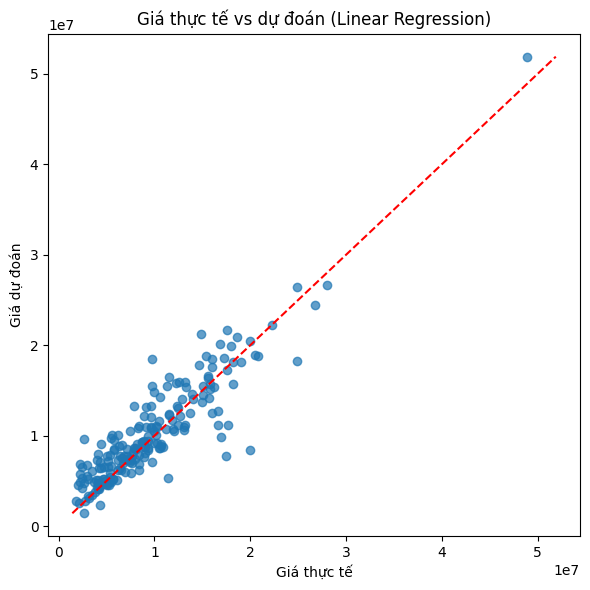

In [105]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.7)
#Trục x là giá thật, trục y là giá dự đoán

min_val = min(y_test.min(), np.min(best_predictions))
max_val = max(y_test.max(), np.max(best_predictions))
#Tìm khoảng GTNN vfa LN để vẽ đường cho vừa


plt.plot([min_val, max_val], [min_val, max_val], "r--")
#Vẽ đường chép đỏ nét đứt
plt.xlabel("Giá thực tế")
plt.ylabel("Giá dự đoán")
plt.title(f"Giá thực tế vs dự đoán ({best_model_name})")
plt.tight_layout()
plt.show()

Biểu đồ cho thấy giá dự đoán bám theo giá thực tế, phù hợp với R^2 khoảng 0,8. Tuy nhiên mô hình có xu hướng đoán cao cho máy giá rẻ và thấp cho máy giá cao, và có một số máy lệch lớn. Nguyên nhân là thông tin dữ liệu chưa đủ, ví dụ như thương hiệu hoặc model đặc biệt

#11. Phân tích lỗi

In [106]:
err = pd.DataFrame({
    "Price_Actual": y_test,
    "Price_Predicted": best_predictions
})
err["Error"] = err["Price_Predicted"] - err["Price_Actual"]       # dương = đoán cao hơn thật
err["Abs_Error"] = err["Error"].abs()
err["Pct_Error"] = err["Abs_Error"] / err["Price_Actual"] * 100   # sai số theo %

print("Đoán cao hơn thật:", (err["Error"] > 0).sum(), "| thấp hơn:", (err["Error"] < 0).sum())
print(f"Sai số trung bình có dấu: {err['Error'].mean():,.0f}")
for t in (10, 20, 30):
    print(f"Số máy sai trong ±{t}%: {(err['Pct_Error'] <= t).mean() * 100:.1f}%")

Đoán cao hơn thật: 118 | thấp hơn: 78
Sai số trung bình có dấu: 604,991
Số máy sai trong ±10%: 41.3%
Số máy sai trong ±20%: 62.2%
Số máy sai trong ±30%: 71.4%


Mô hình đạt mức khá, nhưng vẫn còn gần 40% số máy sai quá 20%

In [107]:
err["Khoang_gia"] = pd.cut(
    err["Price_Actual"],
    bins=[0, 5e6, 10e6, 15e6, 25e6, np.inf],
    labels=["<5tr", "5-10tr", "10-15tr", "15-25tr", ">25tr"]
)
err.groupby("Khoang_gia").agg(
    So_may=("Error", "size"),
    Sai_so_co_dau=("Error", "mean"),
    MAE=("Abs_Error", "mean"),
    Sai_so_pct=("Pct_Error", "mean")
).round(0)

,So_may,Sai_so_co_dau,MAE,Sai_so_pct
Khoang_gia,,,,
<5tr,43,1564651.0,1738037.0,58.0
5-10tr,79,1029973.0,1553676.0,21.0
10-15tr,38,292972.0,1898616.0,16.0
15-25tr,33,-1225103.0,2712729.0,15.0
>25tr,3,-258046.0,2254113.0,7.0


Mô hình bị kéo về giữa: đoán cao cho máy rẻ, đoán thấp cho máy đắt.

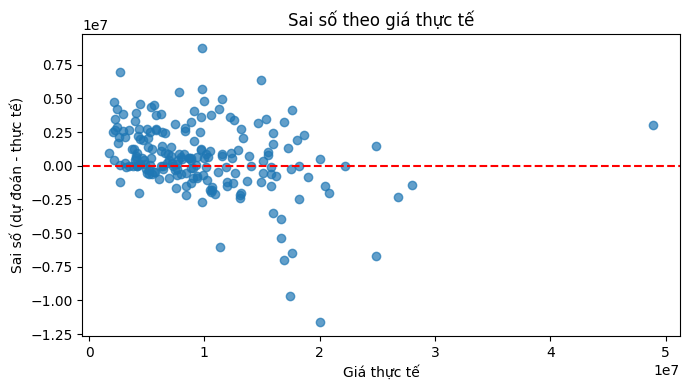

In [108]:
plt.figure(figsize=(7, 4))
plt.scatter(err["Price_Actual"], err["Error"], alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Giá thực tế")
plt.ylabel("Sai số (dự đoán - thực tế)")
plt.title("Sai số theo giá thực tế")
plt.tight_layout()
plt.show()

Biểu đồ xác nhận xu hướng ở bảng: sai số có quy luật theo mức giá, không hoàn toàn ngẫu nhiên.

In [109]:
cols = ["Manufacturer", "Category", "CPU", "GPU", "RAM_GB", "SSD_GB"]
worst = err.sort_values("Abs_Error", ascending=False).head(10).join(X_test[cols])
display(worst[["Price_Actual", "Price_Predicted", "Error"] + cols].round(0))

,Price_Actual,Price_Predicted,Error,Manufacturer,Category,CPU,GPU,RAM_GB,SSD_GB
950,19998108.0,8365485.0,-11632623.0,HP,Workstation,Intel Core i7 6820HQ 2.7GHz,Nvidia Quadro M1000M,8.0,8.0
971,17454818.0,7805376.0,-9649442.0,Dell,Ultrabook,Intel Core i7 6600U 2.6GHz,Intel HD Graphics 520,8.0,256.0
286,9754524.0,18523453.0,8768929.0,Lenovo,Notebook,Intel Core i7 7500U 2.7GHz,Intel HD Graphics 630,8.0,256.0
630,16894800.0,9894454.0,-7000346.0,Asus,Ultrabook,Intel Core i7 7500U 2.7GHz,Intel HD Graphics 620,16.0,512.0
717,2649816.0,9621942.0,6972126.0,Lenovo,Notebook,AMD A6-Series 7310 2GHz,AMD Radeon R4,4.0,0.0
650,24888708.0,18216285.0,-6672423.0,Asus,Gaming,Intel Core i7 6820HK 2.7GHz,Nvidia GeForce GTX 1080,32.0,512.0
65,17632836.0,11171256.0,-6461580.0,Asus,Ultrabook,Intel Core i7 7700HQ 2.8GHz,Nvidia GeForce GTX 1050 Ti,16.0,512.0
587,14876316.0,21245911.0,6369595.0,Lenovo,Ultrabook,Intel Core i7 6600U 2.6GHz,Intel HD Graphics 520,12.0,256.0
901,11372868.0,5325334.0,-6047534.0,Asus,Gaming,Intel Core i7 6820HK 2.7GHz,Nvidia GeForce GTX 980M,32.0,512.0
370,9772308.0,15435338.0,5663030.0,Asus,2 in 1 Convertible,Intel Core i7 7500U 2.7GHz,Nvidia GeForce GT 940MX,12.0,512.0


Mô hình khó đoán máy gaming và workstation; có thể vì cột GPU chưa được khai thác và dữ liệu thiếu thông tin về dòng máy.

In [110]:
e2 = err.join(X_test[["Category", "Manufacturer"]])

display(e2.groupby("Category").agg(
    n=("Error", "size"), MAE=("Abs_Error", "mean"),
    pct=("Pct_Error", "mean"), bias=("Error", "mean")).round(0))

gm = e2.groupby("Manufacturer").agg(
    n=("Error", "size"), MAE=("Abs_Error", "mean"),
    pct=("Pct_Error", "mean"), bias=("Error", "mean"))
display(gm[gm["n"] >= 8].round(0))      # chỉ xét hãng có từ 8 máy test trở lên

,n,MAE,pct,bias
Category,,,,
2 in 1 Convertible,16,2179124.0,21.0,1088749.0
Gaming,33,2451134.0,20.0,922441.0
Netbook,4,2844506.0,107.0,2844506.0
Notebook,113,1428488.0,30.0,828283.0
Ultrabook,25,2482691.0,19.0,-815734.0
Workstation,5,3057597.0,16.0,-2772586.0


,n,MAE,pct,bias
Manufacturer,,,,
Acer,16,873736.0,22.0,351341.0
Asus,27,2681888.0,25.0,-853093.0
Dell,51,1330111.0,14.0,-216288.0
HP,37,2101504.0,33.0,1418446.0
Lenovo,39,2061688.0,37.0,1467641.0
MSI,9,2634339.0,23.0,2634339.0


Chất lượng dự đoán khác nhau giữa các hãng; kết luận ở nhóm ít máy cần thận trọng.

Kết luận: Sai số của mô hình có quy luật (đoán cao máy rẻ, đoán thấp máy đắt và
máy có card rời), nên có thể cải thiện bằng cách dự đoán log(Price) và tách thêm đặc trưng từ GPU/CPU.